Task 4: Heatwaves
In this task we can observe that there was one heatwave in Ås in the given year. When other years were tried using this program, it looked like the amount of heatwves withhin the year hasn't changed much. The mean air temperature may not have gone through drastic changes within the last years. 

In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import requests
from dotenv import load_dotenv


load_dotenv()
client_id = os.getenv("client_id")
print(client_id)


def heat_wave_finder(station_id: str, year: int):
    """The function finds the start aand end of a heatwave for a given station and year.
    It the puts the impormation into a yml-file"""

    # Opens a yml-file, and deletes the existing file if there is one
    with open("heat_wave.yml", mode="w+") as f:
        # Sends a get-request the wanted station-realted information from the Frost-site and decodes it
        station_endpoint = f"https://frost.met.no/sources/v0.jsonld?ids={station_id}"
        station_response = requests.get(station_endpoint, auth=(client_id, ""))
        json_station_data = station_response.json()
        station_name = json_station_data["data"][0]["name"]

        # Retrives the wanted information and puts it in a dictionary
        endpoint = "https://frost.met.no/observations/v0.jsonld"
        parameters_heat_wave = {
            "sources": station_id,
            "elements": "max(air_temperature P1D)",
            "referencetime": f"{year}-01-01/{year}-12-31",
        }

        # Sends a get-request to Frost for the wanted information and decodes it
        heat_wave_response = requests.get(endpoint, parameters_heat_wave, auth=(client_id, ""))
        json_heat_wave_data = heat_wave_response.json()
        data_heat_wave = json_heat_wave_data["data"]

        # Keep track of the relevant dates of the heat wave, stationID and name
        HEAT_WAVE_THRESHOLD = 27
        day_counter = 0
        f.write("dates: \n")

        # Goes through every element in data_heat_wave, and sets the today_is_heat_wave_day variable as False
        for item in data_heat_wave:
            today_is_heat_wave_day = False

            for observation in item["observations"]:
                # Checks if todays value is above the threshold, if so today_is_heat_wave_day is set as True
                if float(observation["value"]) >= HEAT_WAVE_THRESHOLD:
                    today_is_heat_wave_day = True
                    break
            if today_is_heat_wave_day:
                day_counter += 1
            else:
                if day_counter >= 5:
                    # Coverts the date in item to a datetime
                    current_date = pd.to_datetime(item["referenceTime"])
                    # end date: today - 1
                    end_date = current_date - pd.Timedelta(days=1)
                    # start date: today - counter
                    start_date = current_date - pd.Timedelta(days=(day_counter))
                    # Writes the date-interval to the file
                    f.write(f"- {start_date} - {end_date} \n")
                # If the counter is less than 5 after today_is_heat_wave_day = False, it is reset
                day_counter = 0

        # Writes the station id, placename and year to the file
        f.write(f"""station_id: {station_id}
station_name: {station_name}
year: {year}""")


# Calls the function with the wanted parameters for this task
heat_wave_finder("SN17850", 2025)

Task 5: Moving average temperature
This smoothes out the the graph to some degree. We can generally conclude that the temperature is at it highest during the summer-months, wich is not very surprising. We can also see that the temperature varies a fair bit within a single month, but has a almost bell curve shape.

<Axes: xlabel='referencetime', ylabel='value'>

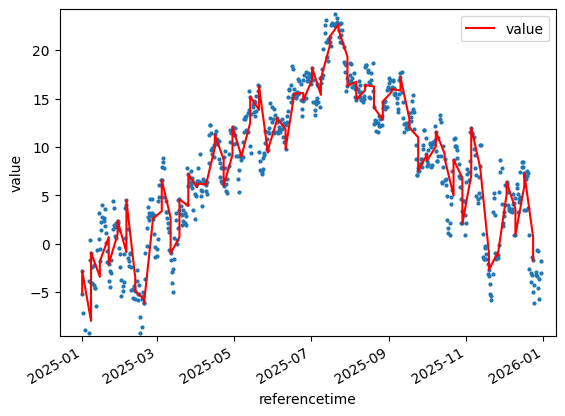

In [263]:
# Retrives the wanted information and puts it in a dictionary
endpoint_avg = "https://frost.met.no/observations/v0.jsonld"
parameters_avg = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Sends a get-request to Frost for the wanted information and decodes it
response_avg = requests.get(endpoint_avg, parameters_avg, auth=(client_id, ""))
json_data_avg = response_avg.json()
data_avg = json_data_avg["data"]

# Creates a dataframe
values_avg = pd.DataFrame()

frames_moving_avg = []
avg_values = []
frames_avg = []

# Retrives the wanted information and appends it to two lists
for e in range(len(data_avg)):
    # Retrives the relevant information from data_avg and appends it to a list
    row = pd.DataFrame(data_avg[e]["observations"])
    row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    row["sources"] = data_avg[e]["sourceId"]
    frames_avg.append(row)

    # Retrives the relevant information, appends it to a list, and calculates the last seven day moving average
    val = data_avg[e]["observations"][0]["value"]
    avg_values.append(val)
    last_seven = avg_values[-7:]
    last_seven_avg = sum(last_seven) / len(last_seven)

    # Appends the seven day moving average to a list
    data_avg[e]["observations"][0]["value"] = last_seven_avg
    avg_row = pd.DataFrame(data_avg[e]["observations"])
    avg_row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    avg_row["sources"] = data_avg[e]["sourceId"]
    frames_moving_avg.append(avg_row)
    seven_day_moving_avg = frames_moving_avg[::7]

# Combines several dataframes
values_avg = pd.concat(frames_avg, ignore_index=True)
moving_values = pd.concat(seven_day_moving_avg, ignore_index=True)

# Plots the values
ax = plt.subplot()
values_avg.plot.scatter(x="referencetime", y="value", s=4, ax=ax)
moving_values.plot(x="referencetime", y="value", ax=ax, color="red")
